# EDA EuroSAT Multiespectral

| Índice en NumPy | Banda | Qué representa | Resolución nativa |
|---:|---|---|---:|
| `0` | **B01** | **Aerosoles costeros.** Banda sensible a partículas en suspensión en la atmósfera. | 60 m |
| `1` | **B02** | **Azul visible.** Canal azul de una composición en color natural. | 10 m |
| `2` | **B03** | **Verde visible.** Canal verde de una composición en color natural. | 10 m |
| `3` | **B04** | **Rojo visible.** Canal rojo de una composición en color natural. La clorofila absorbe parte de la luz en esta región. | 10 m |
| `4` | **B05** | **Borde rojo 1.** Capta el inicio del aumento de reflectancia de la vegetación al pasar del rojo al infrarrojo cercano. | 20 m |
| `5` | **B06** | **Borde rojo 2.** Mide una parte intermedia de esa transición. | 20 m |
| `6` | **B07** | **Borde rojo 3.** Mide la parte de la transición más próxima al infrarrojo cercano. | 20 m |
| `7` | **B08** | **Infrarrojo cercano (NIR).** La vegetación suele reflejar bastante señal en esta banda. Es la que usamos en el falso color. | 10 m |
| `8` | **B09** | **Vapor de agua.** Banda sensible a la absorción por vapor de agua en la atmósfera. | 60 m |
| `9` | **B10** | **Cirros.** Banda del infrarrojo de onda corta que ayuda a detectar nubes altas y finas. | 60 m |
| `10` | **B11** | **Infrarrojo de onda corta 1 (SWIR 1).** Aporta información sobre el contenido de agua de la vegetación y el suelo. | 20 m |
| `11` | **B12** | **Infrarrojo de onda corta 2 (SWIR 2).** Mide una región de mayor longitud de onda que B11 y ayuda a distinguir materiales de la superficie y zonas quemadas. | 20 m |
| `12` | **B8A** | **Infrarrojo cercano estrecho.** Mide un intervalo más estrecho y de mayor longitud de onda que B08. | 20 m |


Fuentes para la descripción y resolución de las bandas. [Copernicus, documentación de Sentinel‑2 L1C](https://documentation.dataspace.copernicus.eu/APIs/SentinelHub/Data/S2L1C.html#available-bands-and-data),  [NASA Earth Observatory, interpretación de bandas visibles e infrarrojas](https://science.nasa.gov/earth/earth-observatory/how-to-interpret-a-false-color-satellite-image/).

In [24]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import rasterio
from rasterio.warp import transform
from tqdm.auto import tqdm
import seaborn as sns

In [12]:
data_dir = Path("data")

ms_paths = sorted((data_dir / "EuroSAT_MS").glob("*/*.tif"))
rgb_paths = sorted((data_dir / "EuroSAT_RGB").glob("*/*.jpg"))

ms = pd.DataFrame({
    "clase": [p.parent.name for p in ms_paths],
    "id_parche": [p.stem for p in ms_paths],
    "ruta_ms": ms_paths,
})

rgb = pd.DataFrame({
    "clase": [p.parent.name for p in rgb_paths],
    "id_parche": [p.stem for p in rgb_paths],
    "ruta_rgb": rgb_paths,
})

inventario = ms.merge(
    rgb,
    on=["clase", "id_parche"],
    how="outer",
    validate="one_to_one",
)

inventario["tiene_ms"] = inventario["ruta_ms"].notna()
inventario["tiene_rgb"] = inventario["ruta_rgb"].notna()
inventario["emparejado"] = inventario["tiene_ms"] & inventario["tiene_rgb"]

resumen = (
    inventario.groupby("clase")[["tiene_ms", "tiene_rgb", "emparejado"]]
    .sum()
    .rename(columns={
        "tiene_ms": "TIFF",
        "tiene_rgb": "JPG",
        "emparejado": "Pares",
    })
)

resumen.loc["Total"] = resumen.sum()
display(resumen)

,TIFF,JPG,Pares
clase,,,
AnnualCrop,3000,3000,3000
Forest,3000,3000,3000
HerbaceousVegetation,3000,3000,3000
Highway,2500,2500,2500
Industrial,2500,2500,2500
Pasture,2000,2000,2000
PermanentCrop,2500,2500,2500
Residential,3000,3000,3000
River,2500,2500,2500


In [14]:
ruta = data_dir / "EuroSAT_MS" / "Forest" / "Forest_1.tif"

with rasterio.open(ruta) as src:
    cubo = src.read()

    print("Forma (bandas, alto, ancho)", cubo.shape)
    print("Tipo de dato", cubo.dtype)
    print("Mínimo y máximo del parche", int(cubo.min()), int(cubo.max()))
    print("Sistema de coordenadas", src.crs)

    # Centro geométrico del parche en el sistema de coordenadas del TIFF
    x, y = src.transform * (src.width / 2, src.height / 2)

    # Convertir ese punto a longitud y latitud en grados
    longitudes, latitudes = transform(src.crs, "EPSG:4326", [x], [y])
    print(f"Centro: latitud {latitudes[0]:.5f}, longitud {longitudes[0]:.5f}")

Forma (bandas, alto, ancho) (13, 64, 64)
Tipo de dato uint16
Mínimo y máximo del parche 7 5087
Sistema de coordenadas EPSG:32632
Centro: latitud 50.25845, longitud 9.46805


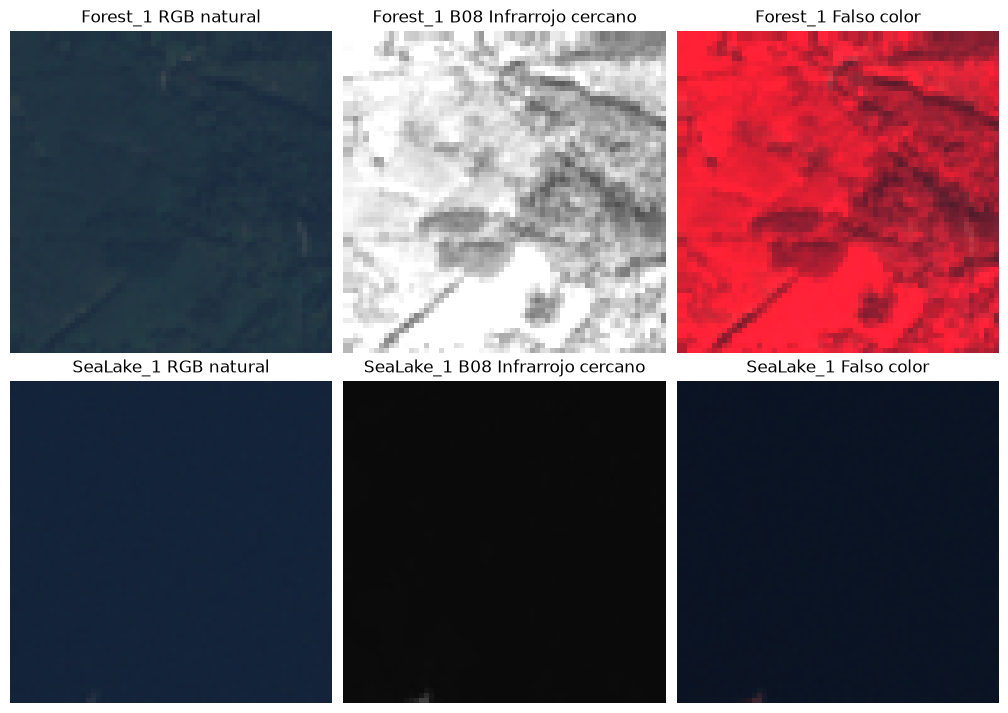

In [17]:
bandas = (
    "B01", "B02", "B03", "B04", "B05", "B06", "B07",
    "B08", "B09", "B10", "B11", "B12", "B8A",
)
indice_banda = {banda: i for i, banda in enumerate(bandas)}

muestras = [
    ("Forest", "Forest_1"),
    ("SeaLake", "SeaLake_1"),
]

cubos = {}
for clase, parche in muestras:
    ruta = data_dir / "EuroSAT_MS" / clase / f"{parche}.tif"
    with rasterio.open(ruta) as src:
        cubos[parche] = src.read()

rgb = [indice_banda[b] for b in ("B04", "B03", "B02")]
falso_color = [indice_banda[b] for b in ("B08", "B04", "B03")]
nir = indice_banda["B08"]

# Un mismo límite de brillo para las tres vistas y ambos parches.
bandas_visibles = [*rgb, nir]
valores = np.stack([cubo[bandas_visibles] for cubo in cubos.values()])
limite = np.percentile(valores, 98)

fig, ejes = plt.subplots(2, 3, figsize=(10, 7), layout="constrained")

for fila, (_, parche) in enumerate(muestras):
    cubo = cubos[parche]

    # imshow espera (alto, ancho, canales) para las imágenes en color
    natural = np.moveaxis(cubo[rgb], 0, -1)
    infrarrojo_rgb = np.moveaxis(cubo[falso_color], 0, -1)

    ejes[fila, 0].imshow(np.clip(natural / limite, 0, 1))
    ejes[fila, 1].imshow(cubo[nir], cmap="gray", vmin=0, vmax=limite)
    ejes[fila, 2].imshow(np.clip(infrarrojo_rgb / limite, 0, 1))

    for eje, titulo in zip(
        ejes[fila], ("RGB natural", "B08 Infrarrojo cercano", "Falso color")
    ):
        eje.set_title(f"{parche} {titulo}")
        eje.axis("off")

plt.show()

In [ ]:
parches_ms = inventario.loc[inventario["tiene_ms"]]
registros_geo = []

with rasterio.Env():
    for parche in tqdm(
        parches_ms.itertuples(index=False),
        total=len(parches_ms),
        desc="Leyendo georreferenciación",
    ):
        with rasterio.open(parche.ruta_ms) as src:
            if src.crs is None:
                raise ValueError(f"Falta el sistema de coordenadas en {parche.ruta_ms}")

            x, y = src.transform * (src.width / 2, src.height / 2)
            registros_geo.append({
                "clase": parche.clase,
                "id_parche": parche.id_parche,
                "crs": src.crs.to_string(),
                "x": x,
                "y": y,
            })

geo = pd.DataFrame(registros_geo)
geo["longitud"] = np.nan
geo["latitud"] = np.nan

# Transformamos juntos los centros que comparten sistema de coordenadas
for crs, grupo in geo.groupby("crs"):
    longitudes, latitudes = transform(
        crs, "EPSG:4326", grupo["x"].to_numpy(), grupo["y"].to_numpy()
    )
    geo.loc[grupo.index, "longitud"] = longitudes
    geo.loc[grupo.index, "latitud"] = latitudes

print(f"Centros calculados: {len(geo):,}")
display(geo[["clase", "id_parche", "latitud", "longitud"]].head())

Leyendo georreferenciación: 100%|██████████| 27000/27000 [00:16<00:00, 1622.49it/s]

Centros calculados: 27,000


,clase,id_parche,latitud,longitud
0,AnnualCrop,AnnualCrop_1,44.035220,28.559055
1,AnnualCrop,AnnualCrop_10,39.085801,-1.829726
2,AnnualCrop,AnnualCrop_100,48.977295,4.239720
3,AnnualCrop,AnnualCrop_1000,48.892610,4.089878
4,AnnualCrop,AnnualCrop_1001,51.832851,18.084960


In [22]:
recuento_utm = (
    geo.groupby("crs")
    .size()
    .rename("n_parches")
    .sort_index()
    .to_frame()
)

recuento_utm["porcentaje"] = (
    100 * recuento_utm["n_parches"] / len(geo)
).round(2)

display(recuento_utm)

,n_parches,porcentaje
crs,,
EPSG:32627,50,0.19
EPSG:32628,45,0.17
EPSG:32629,988,3.66
EPSG:32630,4975,18.43
EPSG:32631,6318,23.40
EPSG:32632,5620,20.81
EPSG:32633,4391,16.26
EPSG:32634,2284,8.46
EPSG:32635,1905,7.06


In [21]:
import plotly.express as px

fig = px.scatter_geo(
    geo,
    lat="latitud",
    lon="longitud",
    color="clase",
    hover_name="id_parche",
    projection="mercator",
    opacity=0.55,
    title="EuroSAT: Ubicación de los parches por clase",
    labels={"clase": "Clase"},
)

fig.update_traces(marker_size=4)
fig.update_geos(
    fitbounds="locations",
    showcountries=True,
    showland=True,
    landcolor="#f0f0f0",
)
fig.update_layout(height=650, margin=dict(l=0, r=0, t=55, b=0))
fig.show()

In [23]:
parches_ms = inventario.loc[
    inventario["tiene_ms"], ["clase", "id_parche", "ruta_ms"]
]
filas = []

with rasterio.Env():
    for parche in tqdm(
        parches_ms.itertuples(index=False),
        total=len(parches_ms),
        desc="Calculando medias por banda",
    ):
        with rasterio.open(parche.ruta_ms) as src:
            cubo = src.read()

        # Forma del cubo: (bandas, alto, ancho).
        # Promediamos alto y ancho para obtener un valor por banda.
        medias = cubo.mean(axis=(1, 2))
        filas.append((parche.clase, parche.id_parche, *medias))

espectral = pd.DataFrame(filas, columns=["clase", "id_parche", *bandas])

candidatas = {
    "B04": "Rojo visible",
    "B05": "Borde rojo",
    "B08": "Infrarrojo cercano",
    "B12": "Infrarrojo de onda corta",
}

display(espectral.groupby("clase")[list(candidatas)].median().round(0))

Calculando medias por banda: 100%|██████████| 27000/27000 [00:30<00:00, 898.41it/s]


,B04,B05,B08,B12
clase,,,,
AnnualCrop,1364.0,1655.0,3092.0,1653.0
Forest,406.0,705.0,2618.0,531.0
HerbaceousVegetation,972.0,1346.0,2336.0,1371.0
Highway,832.0,1152.0,2481.0,1082.0
Industrial,1285.0,1438.0,2112.0,1435.0
Pasture,631.0,1160.0,3389.0,911.0
PermanentCrop,1312.0,1589.0,2776.0,1782.0
Residential,971.0,1215.0,2209.0,1300.0
River,680.0,919.0,1929.0,692.0


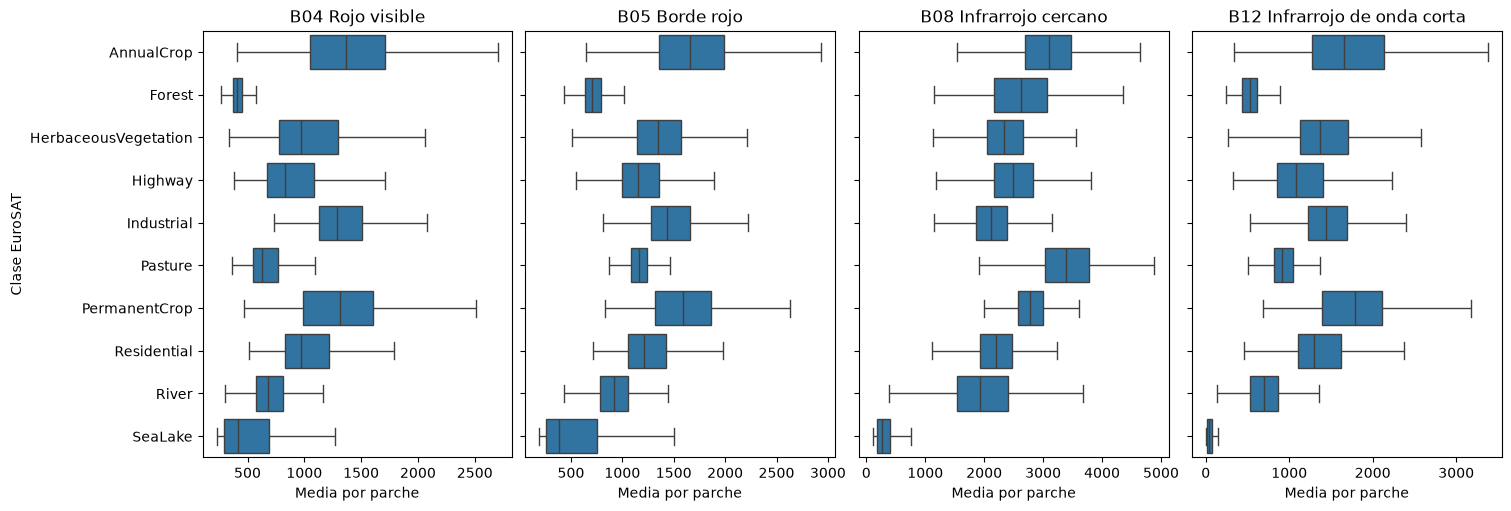

In [26]:
orden_clases = sorted(espectral["clase"].unique())
fig, ejes = plt.subplots(1, 4, figsize=(15, 5), sharey=True, layout="constrained")

for ax, (banda, nombre) in zip(ejes, candidatas.items()):
    sns.boxplot(
        data=espectral,
        x=banda,
        y="clase",
        order=orden_clases,
        showfliers=False,
        ax=ax,
    )
    ax.set_title(f"{banda} {nombre}")
    ax.set_xlabel("Media por parche")
    ax.set_ylabel("")

ejes[0].set_ylabel("Clase EuroSAT")
plt.show()

Cada caja resume las medias de los parches de una clase en una banda. La línea central marca la mediana y la caja contiene el 50 % central de los parches. Una caja más ancha indica que las medias varían más entre los parches de esa clase.

En la banda roja (B04), Forest y SeaLake tienen medianas parecidas. En el infrarrojo cercano (B08), en cambio, sus cajas quedan muy separadas. Esto sugiere que B08 aporta información para distinguir bosque de mar y lago. En esa misma banda, las cajas de Highway y HerbaceousVegetation se solapan. Para distinguir esos parches, podemos explorar otras bandas o características como la textura.

In [28]:
from scipy.signal import correlate2d

kernel_horizontal = [[-1, 1],
                     [ 0, 0]]

kernel_vertical = [[-1, 0],
                   [ 1, 0]]

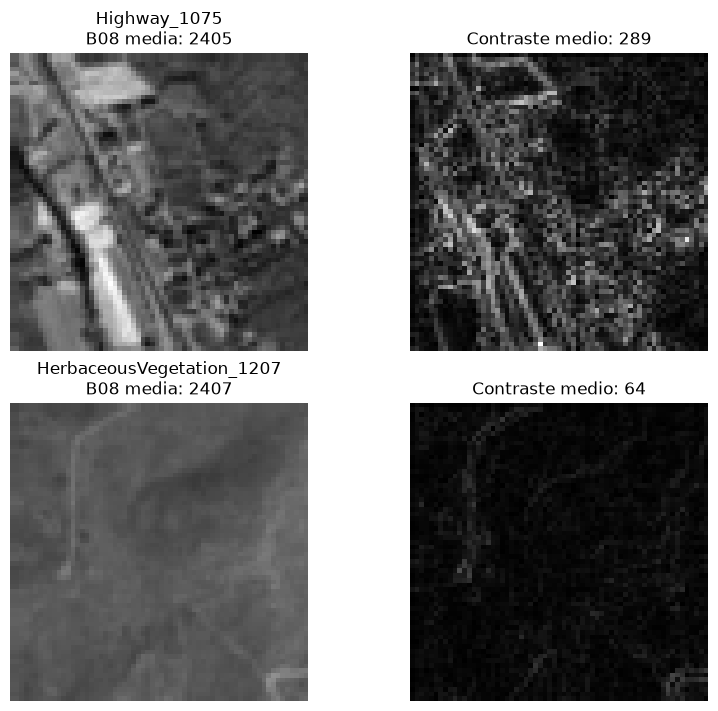

In [29]:
muestras = [
    ("Highway", "Highway_1075"),
    ("HerbaceousVegetation", "HerbaceousVegetation_1207"),
]

resultados = []
for clase, parche in muestras:
    ruta = data_dir / "EuroSAT_MS" / clase / f"{parche}.tif"

    with rasterio.open(ruta) as src:
        # Rasterio numera las bandas desde 1.
        imagen = src.read(8).astype("float32")

    # Usamos la zona donde cada píxel tiene vecino a la derecha y abajo.
    dx = correlate2d(imagen, kernel_horizontal, mode="valid")
    dy = correlate2d(imagen, kernel_vertical, mode="valid")
    contraste = (np.abs(dx) + np.abs(dy)) / 2

    resultados.append((parche, imagen, contraste))

# Una escala común por columna para comparar los dos parches.
vmin = min(imagen.min() for _, imagen, _ in resultados)
vmax = max(imagen.max() for _, imagen, _ in resultados)
vmax_contraste = max(contraste.max() for _, _, contraste in resultados)

fig, ejes = plt.subplots(2, 2, figsize=(8, 7), layout="constrained")

for fila, (parche, imagen, contraste) in enumerate(resultados):
    ejes[fila, 0].imshow(imagen, cmap="gray", vmin=vmin, vmax=vmax)
    ejes[fila, 0].set_title(f"{parche}\nB08 media: {imagen.mean():.0f}")

    ejes[fila, 1].imshow(
        contraste, cmap="gray", vmin=0, vmax=vmax_contraste
    )
    ejes[fila, 1].set_title(f"Contraste medio: {contraste.mean():.0f}")

    for ax in ejes[fila]:
        ax.axis("off")

plt.show()

**Contraste local como característica de textura**

A partir de B08 creamos un mapa de contraste. En cada posición, medimos cuánto cambia el valor respecto a los píxeles vecinos. Las zonas uniformes aparecen oscuras y los bordes, donde el valor cambia de golpe, aparecen claros. Este mapa es una imagen derivada de B08.

Para la práctica, guardamos un solo número por parche: el promedio de los valores del mapa de contraste. Así podemos añadirlo como una columna al vector de características de k-means. En nuestro ejemplo, los dos parches tienen casi la misma media en B08 (2405 y 2407), pero su contraste medio es distinto (289 y 64). La media de B08 resume el nivel de señal del parche y el contraste medio resume cuánto cambia esa señal entre píxeles vecinos.

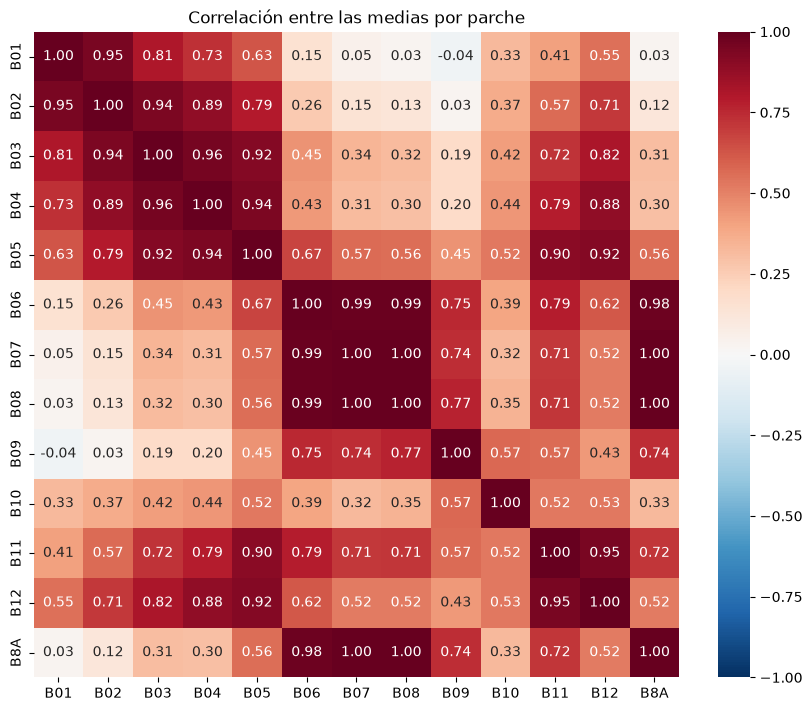

In [31]:
correlacion = espectral[list(bandas)].corr(method="pearson")

fig, ax = plt.subplots(figsize=(9, 7), layout="constrained")
sns.heatmap(
    correlacion,
    ax=ax,
    cmap="RdBu_r",
    vmin=-1,
    vmax=1,
    center=0,
    annot=True,
    fmt=".2f",
    square=True,
)
ax.set_title("Correlación entre las medias por parche")
plt.show()

Cada celda indica si las medias de dos bandas suben o bajan juntas de un parche a otro. Un valor cercano a 1 indica que suelen variar en la misma dirección. Un valor cercano a 0 indica que hay poca relación lineal entre ellas.
- Las bandas RGB varían juntas. B02, B03 y B04 tienen correlaciones entre 0,89 y 0,96. B05 también está muy correlacionada con el rojo (0,94), así que parte de lo que aporta su media podría estar ya recogido en RGB.
- B08 sigue un patrón distinto al RGB. Sus correlaciones con las bandas visibles están entre 0,13 y 0,32. En cambio, B06, B07, B08 y B8A tienen correlaciones entre 0,98 y 1,00 al redondear. Por eso tiene sentido empezar añadiendo solo B08 como representante de ese grupo.
- B11 y B12 también varían juntas. Su correlación es 0,95, así que podemos probar una de las dos primero para ver qué añade el infrarrojo de onda corta.
El mapa compara medias por parche. Dos bandas con medias muy correlacionadas todavía pueden mostrar texturas distintas. Para la práctica, este resultado justifica una primera comparación sencilla: RGB frente a RGB + B08.

In [32]:
bandas_textura = ["B07", "B08", "B8A"]
indices_rasterio = [7, 8, 13]  # Rasterio numera las bandas desde 1.

parches_ms = inventario.loc[
    inventario["tiene_ms"], ["clase", "id_parche", "ruta_ms"]
]
filas = []

with rasterio.Env():
    for parche in tqdm(
        parches_ms.itertuples(index=False),
        total=len(parches_ms),
        desc="Calculando contraste por banda",
    ):
        with rasterio.open(parche.ruta_ms) as src:
            cubo = src.read(indices_rasterio, out_dtype="float32")

        centro = cubo[:, :-1, :-1]
        dx = cubo[:, :-1, 1:] - centro
        dy = cubo[:, 1:, :-1] - centro

        mapas_contraste = (np.abs(dx) + np.abs(dy)) / 2
        contrastes = mapas_contraste.mean(axis=(1, 2))

        filas.append((parche.clase, parche.id_parche, *contrastes))

textura = pd.DataFrame(filas, columns=["clase", "id_parche", *bandas_textura])

display(textura[bandas_textura].corr().round(3))

Calculando contraste por banda: 100%|██████████| 27000/27000 [00:28<00:00, 939.16it/s] 


,B07,B08,B8A
B07,1.000,0.854,0.995
B08,0.854,1.000,0.862
B8A,0.995,0.862,1.000


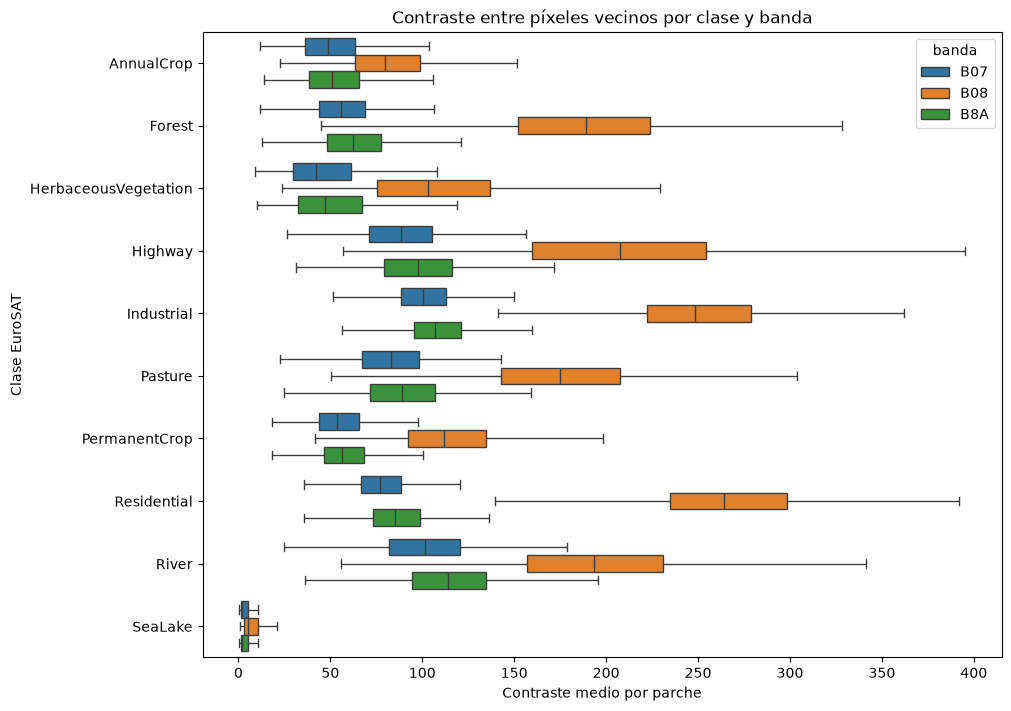

In [33]:
import matplotlib.pyplot as plt
import seaborn as sns

textura_larga = textura.melt(
    id_vars=["clase", "id_parche"],
    value_vars=bandas_textura,
    var_name="banda",
    value_name="contraste_medio",
)

fig, ax = plt.subplots(figsize=(10, 7), layout="constrained")
sns.boxplot(
    data=textura_larga,
    x="contraste_medio",
    y="clase",
    hue="banda",
    showfliers=False,
    ax=ax,
)
ax.set(
    title="Contraste entre píxeles vecinos por clase y banda",
    xlabel="Contraste medio por parche",
    ylabel="Clase EuroSAT",
)
plt.show()

**Contraste entre píxeles vecinos**
Para cada parche y cada banda (B07, B08 y B8A), calculamos cuánto cambia el valor de cada píxel respecto a sus vecinos de la derecha y de abajo. Tomamos el valor absoluto de ambas diferencias y las promediamos. Después hacemos la media de todos esos cambios locales para obtener un valor de contraste por parche y banda.

**Interpretación de los boxplots**
Cada caja resume el contraste de los parches de una clase en una banda. La línea interior marca la mediana y la caja abarca el 50 % central. SeaLake tiene un contraste bajo en las tres bandas, lo que indica que los píxeles vecinos suelen tener valores parecidos. En B08, Residential e Industrial presentan contrastes altos, pero sus cajas se solapan. Esta medida ayuda a distinguir escenas uniformes de otras con más cambios locales, aunque por sí sola separa mal esas dos clases.

**Por qué empezamos con B08**
B07 y B8A dan contrastes muy parecidos entre parches, con una correlación de 0,995. B08 muestra un patrón algo distinto. Por ejemplo, Residential tiene la mediana de contraste más alta en B08, mientras que en B07 y B8A queda por debajo de River e Industrial. Además, B08 se capta a 10 m de resolución nativa, frente a los 20 m de B07 y B8A, que se interpolan a la rejilla de EuroSAT. Por eso, para la primera prueba, añadimos solo el contraste de B08 como característica de textura.